In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats
import seaborn as sns
import statsmodels.formula.api as sm

-----------------------------------------------------------------------------------------------------------

данные уч_data4-6.gdt
дома взять и сделать как кейс (по данным из группы)
построить модель зависимости среднедушевого дохода от безработицы. может быть похоже на кривую филлипса, нарисовать график, выявить типы зависимости (линейные или ещё какие-то), степенные зависимости к примеру. применить МНК, ВМНК, дать интерпретацию, попробовать нелинейный метод наименьших квадратов. на фотографии способы задания МНК в gretl. 
попробовать спецификации, выбрать 2-3 модели наиболее похожие с точки зрения экономики (дать интерпретацию), оценить коэффициенты с помощью НМНК и методов или другие подобные, перед этим проведя диагностику нелинейности для данных

In [2]:
from scipy.optimize import curve_fit
from scipy import stats

In [3]:
df = pd.read_csv('ex_data4-6.csv')

In [4]:
df.columns

Index(['unemp', 'medinc'], dtype='str')

<Axes: xlabel='unemp', ylabel='medinc'>

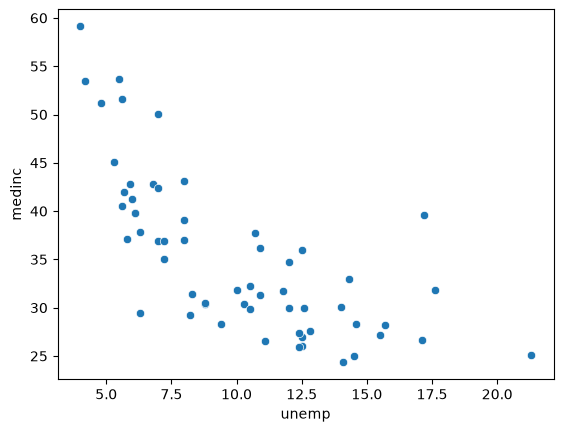

In [5]:
sns.scatterplot(y=df['medinc'], x=df['unemp'])

In [6]:
mnk = sm.ols('medinc ~ unemp', df).fit()
mnk.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 medinc   R-squared:                       0.510
Model:                            OLS   Adj. R-squared:                  0.502
Method:                 Least Squares   F-statistic:                     58.38
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           3.03e-10
Time:                        18:18:56   Log-Likelihood:                -183.58
No. Observations:                  58   AIC:                             371.2
Df Residuals:                      56   BIC:                             375.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     50.2761      2.100     23.942      0.000      46.070      54.483
unemp         -1.5011      0.196     -7.641      0.000      -1.895      -1.108
==============================================================================
Omnibus:                        5.899   Durbin-Watson:                   2.299
Prob(Omnibus):                  0.052   Jarque-Bera (JB):                5.275
Skew:                           0.731   Prob(JB):                       0.0715
Kurtosis:                       3.207   Cond. No.                         29.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

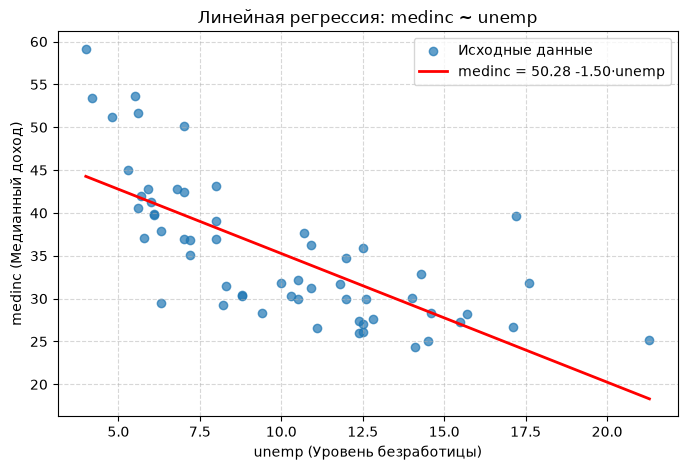

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Извлекаем коэффициенты напрямую из модели
b = mnk.params['Intercept']  # 50.2761
k = mnk.params['unemp']  # -1.5011

# 2. Создаем массив значений X в пределах данных из df
x_vals = np.linspace(df['unemp'].min(), df['unemp'].max(), 100)
y_vals = k * x_vals + b

# 3. Строим график
plt.figure(figsize=(8, 5))

# Исходные точки из датафрейма
plt.scatter(df['unemp'], df['medinc'], alpha=0.7, label='Исходные данные')

# Линия регрессии
plt.plot(
    x_vals,
    y_vals,
    color='red',
    linewidth=2,
    label=f'medinc = {b:.2f} {k:.2f}·unemp',
)

# Оформление
plt.xlabel('unemp (Уровень безработицы)')
plt.ylabel('medinc (Медианный доход)')
plt.title('Линейная регрессия: medinc ~ unemp')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()


Тест Рамсея RESET:
F-статистика: 20.0897
p-value: 0.0000
Вывод: Отклоняем гипотезу о линейности (присутствует нелинейность)


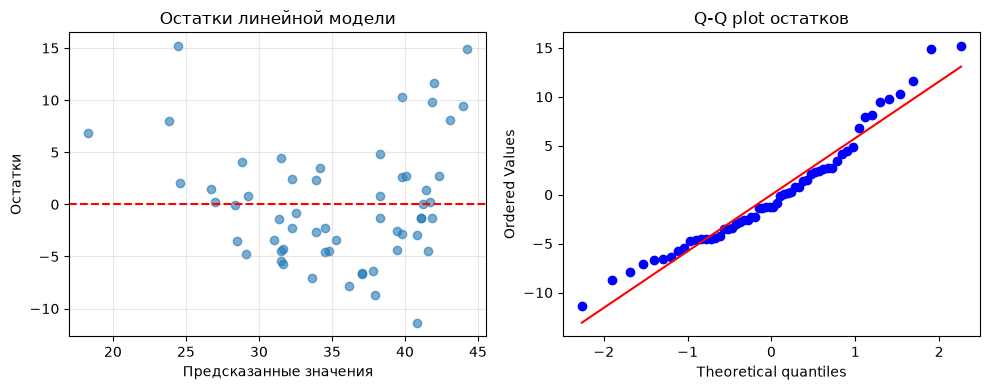

In [8]:
# Тест на нелинейность (тест Рамсея RESET)
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

X = df['unemp'].values.reshape(-1, 1)
y = df['medinc'].values

# Линейная модель
lin_model = LinearRegression()
lin_model.fit(X, y)
y_pred_lin = lin_model.predict(X)

# Добавляем квадрат и куб предсказанных значений
X_reset = np.column_stack([y_pred_lin, y_pred_lin**2, y_pred_lin**3])
X_reset_const = np.column_stack([np.ones(len(X_reset)), X_reset])

# Регрессия RESET
reset_model = np.linalg.lstsq(X_reset_const, y, rcond=None)[0]
y_pred_reset = X_reset_const @ reset_model

# F-тест
ssr_lin = np.sum((y - y_pred_lin)**2)
ssr_reset = np.sum((y - y_pred_reset)**2)
n = len(y)
k = 1
q = 2  # количество добавленных переменных

f_stat = ((ssr_lin - ssr_reset) / q) / (ssr_reset / (n - k - q - 1))
p_value = 1 - stats.f.cdf(f_stat, q, n - k - q - 1)

print(f"Тест Рамсея RESET:")
print(f"F-статистика: {f_stat:.4f}")
print(f"p-value: {p_value:.4f}")
if p_value < 0.05:
    print("Вывод: Отклоняем гипотезу о линейности (присутствует нелинейность)")
else:
    print("Вывод: Не отвергаем гипотезу о линейности")

# Визуализация остатков
residuals = y - y_pred_lin
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(y_pred_lin, residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Остатки линейной модели')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q plot остатков')
plt.tight_layout()
plt.show()

In [9]:
# medinc = β0 + β1*unemp + ε
lin_coef = np.polyfit(df['unemp'], df['medinc'], 1)
print(f"Линейная модель (МНК): medinc = {lin_coef[1]:.4f} + {lin_coef[0]:.4f}*unemp")

Линейная модель (МНК): medinc = 50.2761 + -1.5011*unemp


In [10]:
# medinc = β0 + β1*unemp + β2*unemp² + ε
poly_coef = np.polyfit(df['unemp'], df['medinc'], 2)
print(f"Квадратичная: medinc = {poly_coef[2]:.4f} + {poly_coef[1]:.4f}*unemp + {poly_coef[0]:.4f}*unemp²")

Квадратичная: medinc = 69.3242 + -5.4673*unemp + 0.1788*unemp²


In [11]:
# medinc = β0 + β1*ln(unemp) + ε
log_model = np.polyfit(np.log(df['unemp']), df['medinc'], 1)
print(f"Логарифмическая: medinc = {log_model[1]:.4f} + {log_model[0]:.4f}*ln(unemp)")

Логарифмическая: medinc = 71.3514 + -16.2231*ln(unemp)


In [12]:
# medinc = β0 + β1*exp(-β2*unemp) + ε
def exponential_model(x, a, b, c):
    return a + b * np.exp(-c * x)

popt_exp, pcov_exp = curve_fit(exponential_model, df['unemp'], df['medinc'], 
                                p0=[df['medinc'].min(), df['medinc'].max()-df['medinc'].min(), 1])
print(f"Экспоненциальная (НМНК): medinc = {popt_exp[0]:.4f} + {popt_exp[1]:.4f}*exp(-{popt_exp[2]:.4f}*unemp)")

C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


Экспоненциальная (НМНК): medinc = 28.6903 + 130.2313*exp(-0.3769*unemp)


In [13]:
# medinc = β0 + β1/unemp + ε
inv_model = np.polyfit(1/df['unemp'], df['medinc'], 1)
print(f"Обратная: medinc = {inv_model[1]:.4f} + {inv_model[0]:.4f}/unemp")

Обратная: medinc = 18.3666 + 144.3074/unemp


In [14]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.api import OLS, add_constant

# Линейная модель для тестов
X_const = add_constant(df['unemp'])
ols_model = OLS(df['medinc'], X_const).fit()
residuals_ols = ols_model.resid

# Тест Бройша-Пагана
bp_stat, bp_pvalue, bp_fstat, bp_fpvalue = het_breuschpagan(residuals_ols, X_const)
print(f"Тест Бройша-Пагана на гетероскедастичность:")
print(f"  LM-статистика: {bp_stat:.4f}, p-value: {bp_pvalue:.4f}")

# Тест Уайта
white_stat, white_pvalue, white_fstat, white_fpvalue = het_white(residuals_ols, X_const)
print(f"Тест Уайта на гетероскедастичность:")
print(f"  Статистика: {white_stat:.4f}, p-value: {white_pvalue:.4f}")

if bp_pvalue < 0.05 or white_pvalue < 0.05:
    print("\nВывод: Присутствует гетероскедастичность → необходимо применить ВМНК")
else:
    print("\nВывод: Гетероскедастичность не обнаружена (ВМНК не обязателен, но можно проверить)")

Тест Бройша-Пагана на гетероскедастичность:
  LM-статистика: 0.7488, p-value: 0.3869
Тест Уайта на гетероскедастичность:
  Статистика: 9.2414, p-value: 0.0098

Вывод: Присутствует гетероскедастичность → необходимо применить ВМНК


In [15]:
# Веса: w_i = 1/unemp_i
weights_inv_x = 1 / df['unemp'].values

# ВМНК: минимизируем Σ w_i * (y_i - ŷ_i)²
# В statsmodels это делается через WLS
from statsmodels.api import WLS

X_const = add_constant(df['unemp'])
wls_model_1 = WLS(df['medinc'], X_const, weights=weights_inv_x).fit()

print(f"\nВМНК (веса = 1/unemp):")
print(f"  medinc = {wls_model_1.params['const']:.4f} + {wls_model_1.params['unemp']:.4f}*unemp")
print(f"  R²: {wls_model_1.rsquared:.4f}")
print(f"  F-статистика: {wls_model_1.fvalue:.4f}")
print(wls_model_1.summary())


ВМНК (веса = 1/unemp):
  medinc = 54.3315 + -1.9086*unemp
  R²: 0.5533
  F-статистика: 69.3633
                            WLS Regression Results                            
Dep. Variable:                 medinc   R-squared:                       0.553
Model:                            WLS   Adj. R-squared:                  0.545
Method:                 Least Squares   F-statistic:                     69.36
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           2.23e-11
Time:                        18:18:59   Log-Likelihood:                -188.71
No. Observations:                  58   AIC:                             381.4
Df Residuals:                      56   BIC:                             385.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------

In [16]:
# Веса: w_i = 1/unemp_i²
weights_inv_x2 = 1 / (df['unemp'].values ** 2)

wls_model_2 = WLS(df['medinc'], X_const, weights=weights_inv_x2).fit()

print(f"\nВМНК (веса = 1/unemp²):")
print(f"  medinc = {wls_model_2.params['const']:.4f} + {wls_model_2.params['unemp']:.4f}*unemp")
print(f"  R²: {wls_model_2.rsquared:.4f}")
print(f"  F-статистика: {wls_model_2.fvalue:.4f}")
print(wls_model_2.summary())


ВМНК (веса = 1/unemp²):
  medinc = 58.5359 + -2.4030*unemp
  R²: 0.5714
  F-статистика: 74.6501
                            WLS Regression Results                            
Dep. Variable:                 medinc   R-squared:                       0.571
Model:                            WLS   Adj. R-squared:                  0.564
Method:                 Least Squares   F-statistic:                     74.65
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           6.92e-12
Time:                        18:18:59   Log-Likelihood:                -196.57
No. Observations:                  58   AIC:                             397.1
Df Residuals:                      56   BIC:                             401.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------

In [17]:
# Шаг 1: Оцениваем обычным МНК
ols_model = OLS(df['medinc'], X_const).fit()
y_pred_ols = ols_model.fittedvalues

# Шаг 2: Строим веса как 1/ŷ² (если дисперсия пропорциональна квадрату предсказанного значения)
weights_inv_yhat2 = 1 / (y_pred_ols ** 2)

# Шаг 3: Оцениваем ВМНК с новыми весами
wls_model_3 = WLS(df['medinc'], X_const, weights=weights_inv_yhat2).fit()

print(f"\nВМНК (веса = 1/ŷ², итеративный FGLS):")
print(f"  medinc = {wls_model_3.params['const']:.4f} + {wls_model_3.params['unemp']:.4f}*unemp")
print(f"  R²: {wls_model_3.rsquared:.4f}")
print(f"  F-статистика: {wls_model_3.fvalue:.4f}")
print(wls_model_3.summary())


ВМНК (веса = 1/ŷ², итеративный FGLS):
  medinc = 46.6822 + -1.1528*unemp
  R²: 0.4573
  F-статистика: 47.1910
                            WLS Regression Results                            
Dep. Variable:                 medinc   R-squared:                       0.457
Model:                            WLS   Adj. R-squared:                  0.448
Method:                 Least Squares   F-statistic:                     47.19
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           5.68e-09
Time:                        18:18:59   Log-Likelihood:                -183.61
No. Observations:                  58   AIC:                             371.2
Df Residuals:                      56   BIC:                             375.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

In [18]:
# Взвешенный НМНК для экспоненциальной модели
# Минимизируем: Σ w_i * (y_i - (β0 + β1*exp(-β2*x_i)))²

def weighted_nls_objective(params, x, y, weights):
    """Функция потерь для взвешенного НМНК"""
    b0, b1, b2 = params
    y_pred = b0 + b1 * np.exp(-b2 * x)
    residuals = y - y_pred
    return np.sum(weights * residuals**2)

from scipy.optimize import minimize

# Веса: 1/unemp
weights_nls = 1 / df['unemp'].values

# Начальные приближения
initial_params = [df['medinc'].min(), df['medinc'].max()-df['medinc'].min(), 1.0]

# Оптимизация
result_weighted_nls = minimize(
    weighted_nls_objective,
    initial_params,
    args=(df['unemp'].values, df['medinc'].values, weights_nls),
    method='L-BFGS-B'
)

popt_weighted_nls = result_weighted_nls.x
print(f"\nВзвешенный НМНК (веса = 1/unemp) для экспоненциальной модели:")
print(f"  medinc = {popt_weighted_nls[0]:.4f} + {popt_weighted_nls[1]:.4f}*exp(-{popt_weighted_nls[2]:.4f}*unemp)")


Взвешенный НМНК (веса = 1/unemp) для экспоненциальной модели:
  medinc = 28.7679 + 133.2003*exp(-0.3821*unemp)


In [19]:
def calculate_metrics(y_true, y_pred, n_params, weights=None):
    """Расчет метрик качества модели (с учетом весов если есть)"""
    n = len(y_true)
    
    if weights is not None:
        # Взвешенные метрики
        ss_res = np.sum(weights * (y_true - y_pred)**2)
        ss_tot = np.sum(weights * (y_true - np.average(y_true, weights=weights))**2)
    else:
        ss_res = np.sum((y_true - y_pred)**2)
        ss_tot = np.sum((y_true - np.mean(y_true))**2)
    
    r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0
    adj_r_squared = 1 - (1 - r_squared) * (n - 1) / (n - n_params - 1)
    
    if weights is not None:
        aic = n * np.log(ss_res/n) + 2 * n_params
        bic = n * np.log(ss_res/n) + n_params * np.log(n)
    else:
        aic = n * np.log(ss_res/n) + 2 * n_params
        bic = n * np.log(ss_res/n) + n_params * np.log(n)
    
    if weights is not None:
        rmse = np.sqrt(np.sum(weights * (y_true - y_pred)**2) / np.sum(weights))
    else:
        rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    
    return r_squared, adj_r_squared, aic, bic, rmse

# Собираем все модели
models = {
    'Линейная (МНК)': (lin_coef[1] + lin_coef[0]*df['unemp'], 2, None),
    'Квадратичная': (np.polyval(poly_coef, df['unemp']), 3, None),
    'Логарифмическая': (log_model[1] + log_model[0]*np.log(df['unemp']), 2, None),
    'Экспоненциальная (НМНК)': (exponential_model(df['unemp'], *popt_exp), 3, None),
    'Обратная': (inv_model[1] + inv_model[0]/df['unemp'], 2, None),
    'ВМНК (1/unemp)': (wls_model_1.fittedvalues, 2, weights_inv_x),
    'ВМНК (1/unemp²)': (wls_model_2.fittedvalues, 2, weights_inv_x2),
    'ВМНК (1/ŷ²)': (wls_model_3.fittedvalues, 2, weights_inv_yhat2),
    'Взвешенный НМНК (1/unemp)': (popt_weighted_nls[0] + popt_weighted_nls[1]*np.exp(-popt_weighted_nls[2]*df['unemp']), 3, weights_nls)
}

results = []
for name, (y_pred, n_params, weights) in models.items():
    r2, adj_r2, aic, bic, rmse = calculate_metrics(df['medinc'].values, y_pred, n_params, weights)
    results.append({
        'Модель': name,
        'R²': r2,
        'Adj R²': adj_r2,
        'AIC': aic,
        'BIC': bic,
        'RMSE': rmse
    })

results_df = pd.DataFrame(results)
print("\nСравнение всех моделей (включая ВМНК):")
print(results_df.to_string(index=False))

# Выбор топ-3 моделей по Adjusted R²
top_models = results_df.nlargest(3, 'Adj R²')
print("\n" + "="*70)
print("ТОП-3 МОДЕЛИ ПО ADJUSTED R²")
print("="*70)
print(top_models[['Модель', 'R²', 'Adj R²', 'AIC', 'BIC', 'RMSE']].to_string(index=False))

# Выбор лучшей модели по AIC (информационный критерий)
best_by_aic = results_df.loc[results_df['AIC'].idxmin()]
print(f"\nЛучшая модель по AIC: {best_by_aic['Модель']} (AIC = {best_by_aic['AIC']:.2f})")

# Выбор лучшей модели по BIC
best_by_bic = results_df.loc[results_df['BIC'].idxmin()]
print(f"Лучшая модель по BIC: {best_by_bic['Модель']} (BIC = {best_by_bic['BIC']:.2f})")


Сравнение всех моделей (включая ВМНК):
                   Модель       R²   Adj R²         AIC         BIC     RMSE
           Линейная (МНК) 0.510392 0.492588  206.555387  210.676273 5.732588
             Квадратичная 0.663639 0.644952  186.781050  192.962379 4.751486
          Логарифмическая 0.624438 0.610781  191.174879  195.295765 5.020736
  Экспоненциальная (НМНК) 0.719628 0.704052  176.221146  182.402475 4.338045
                 Обратная 0.699073 0.688130  178.324706  182.445592 4.494252
           ВМНК (1/unemp) 0.553298 0.537055   88.061179   92.182065 6.018761
          ВМНК (1/unemp²) 0.571374 0.555788  -24.968422  -20.847536 6.142555
              ВМНК (1/ŷ²) 0.457317 0.437583 -205.137667 -201.016781 5.526450
Взвешенный НМНК (1/unemp) 0.757744 0.744285   54.571245   60.752574 4.432367

ТОП-3 МОДЕЛИ ПО ADJUSTED R²
                   Модель       R²   Adj R²        AIC        BIC     RMSE
Взвешенный НМНК (1/unemp) 0.757744 0.744285  54.571245  60.752574 4.432367
  Экспоненц

ДИАГНОСТИКА ОСТАТКОВ ЛУЧШЕЙ МОДЕЛИ (Экспоненциальная НМНК)
Тест Шапиро-Уилка на нормальность: W = 0.9469, p-value = 0.0131
Тест Харке-Бера на нормальность:   JB = 4.8399, p-value = 0.0889
→ Вывод: Есть отклонения от нормальности (допустимо при наличии робастных ошибок).

Тест Бройша-Пагана на гетероскедастичность: LM = 0.3023, p-value = 0.5825
Тест Уайта на гетероскедастичность:          χ² = 0.7535, p-value = 0.6861
→ Вывод: Гетероскедастичность устранена! Спецификация модели адекватна.


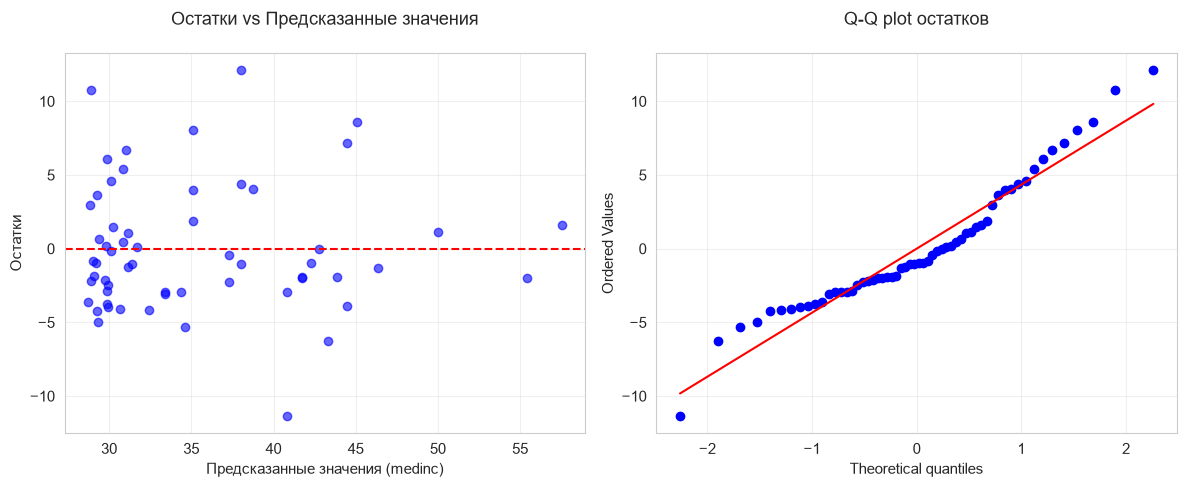

In [24]:
import scipy.stats as stats
from statsmodels.stats.diagnostic import het_white, het_breuschpagan
from statsmodels.api import add_constant
import matplotlib.pyplot as plt

# 1. Получаем остатки лучшей модели (Экспоненциальная НМНК)
y_pred_best = exponential_model(df['unemp'], *popt_exp)
residuals_best = df['medinc'].values - y_pred_best

# 2. Тест на нормальность (Шапиро-Уилка и Харке-Бера)
shapiro_stat, shapiro_p = stats.shapiro(residuals_best)

# ИСПРАВЛЕНО: jarque_bera в новых версиях scipy возвращает только 2 значения
jb_result = stats.jarque_bera(residuals_best)
jb_stat = jb_result.statistic   # или jb_result[0]
jb_p = jb_result.pvalue         # или jb_result[1]

print("="*60)
print("ДИАГНОСТИКА ОСТАТКОВ ЛУЧШЕЙ МОДЕЛИ (Экспоненциальная НМНК)")
print("="*60)
print(f"Тест Шапиро-Уилка на нормальность: W = {shapiro_stat:.4f}, p-value = {shapiro_p:.4f}")
print(f"Тест Харке-Бера на нормальность:   JB = {jb_stat:.4f}, p-value = {jb_p:.4f}")
if shapiro_p > 0.05 and jb_p > 0.05:
    print("→ Вывод: Гипотеза о нормальности остатков НЕ отвергается (это хорошо).")
else:
    print("→ Вывод: Есть отклонения от нормальности (допустимо при наличии робастных ошибок).")

# 3. Тест на гетероскедастичность
X_test = add_constant(df['unemp'])
white_stat, white_p, white_f, white_fp = het_white(residuals_best, X_test)
bp_stat, bp_p, bp_f, bp_fp = het_breuschpagan(residuals_best, X_test)

print(f"\nТест Бройша-Пагана на гетероскедастичность: LM = {bp_stat:.4f}, p-value = {bp_p:.4f}")
print(f"Тест Уайта на гетероскедастичность:          χ² = {white_stat:.4f}, p-value = {white_p:.4f}")
if white_p > 0.05:
    print("→ Вывод: Гетероскедастичность устранена! Спецификация модели адекватна.")
else:
    print("→ Вывод: Гетероскедастичность сохраняется (рекомендуется использовать робастные стандартные ошибки).")

# 4. Визуализация остатков
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_pred_best, residuals_best, alpha=0.6, color='blue')
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Предсказанные значения (medinc)')
plt.ylabel('Остатки')
plt.title('Остатки vs Предсказанные значения\n')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
stats.probplot(residuals_best, dist="norm", plot=plt)
plt.title('Q-Q plot остатков\n')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Exp_model_residuals.png', dpi=300)
plt.show()

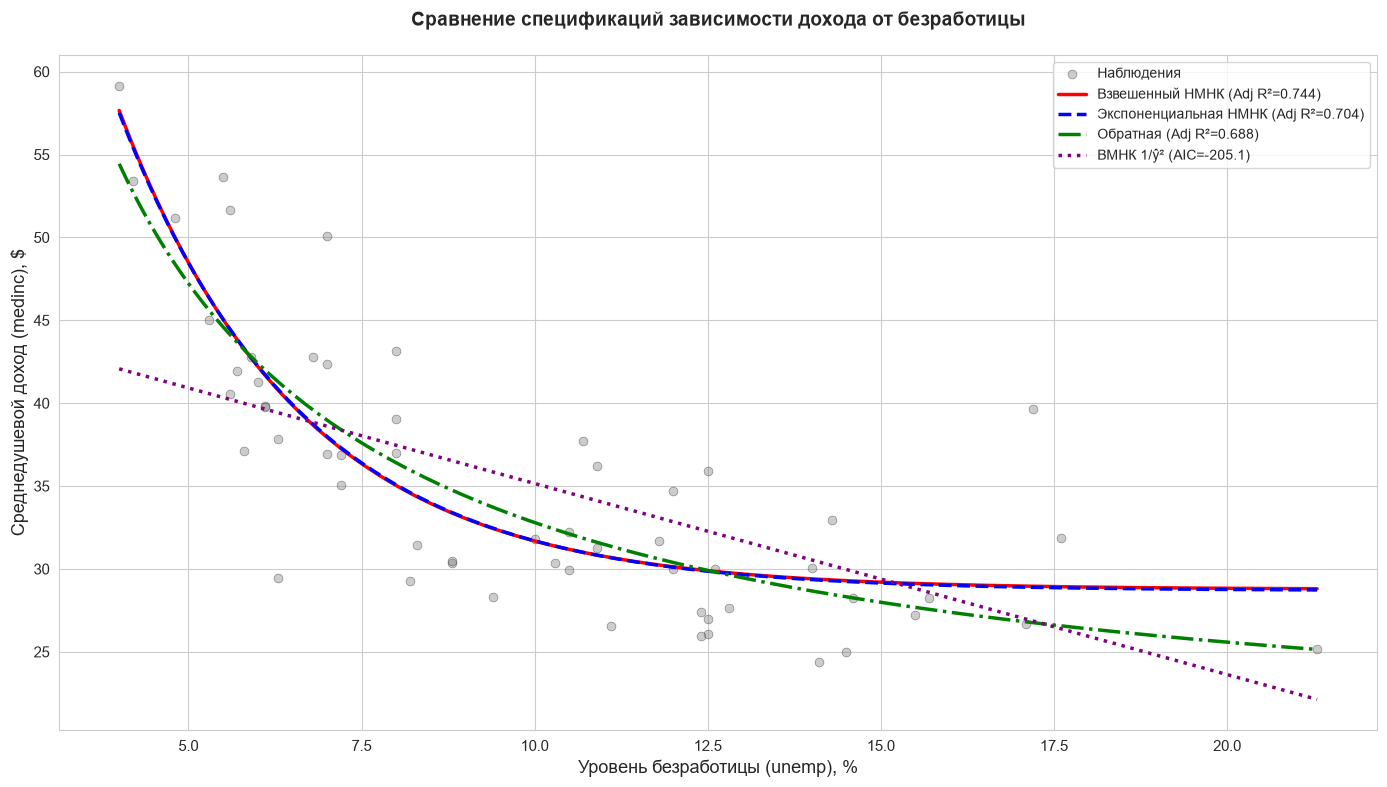

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 12)
plt.rcParams['font.size'] = 11

x_range = np.linspace(df['unemp'].min(), df['unemp'].max(), 200)

# ========== ГРАФИК 1: Все топ-модели на одном графике ==========
plt.figure(figsize=(14, 8))
plt.scatter(df['unemp'], df['medinc'], alpha=0.4, s=40, 
            label='Наблюдения', color='gray', edgecolors='black', linewidth=0.5)

# Взвешенный НМНК (лучший по Adj R²)
y_wnls = popt_weighted_nls[0] + popt_weighted_nls[1]*np.exp(-popt_weighted_nls[2]*x_range)
plt.plot(x_range, y_wnls, linewidth=2.5, label=f'Взвешенный НМНК (Adj R²={0.744:.3f})', 
         color='red', linestyle='-')

# Экспоненциальная НМНК (2-я по Adj R²)
y_enls = exponential_model(x_range, *popt_exp)
plt.plot(x_range, y_enls, linewidth=2.5, label=f'Экспоненциальная НМНК (Adj R²={0.704:.3f})', 
         color='blue', linestyle='--')

# Обратная (3-я по Adj R²)
y_inv = inv_model[1] + inv_model[0]/x_range
plt.plot(x_range, y_inv, linewidth=2.5, label=f'Обратная (Adj R²={0.688:.3f})', 
         color='green', linestyle='-.')

# ВМНК (1/ŷ²) — лучшая по AIC/BIC
X_plot = add_constant(x_range)
y_wls_fgls = wls_model_3.predict(X_plot)
plt.plot(x_range, y_wls_fgls, linewidth=2.5, label=f'ВМНК 1/ŷ² (AIC={-205.14:.1f})', 
         color='purple', linestyle=':')

plt.xlabel('Уровень безработицы (unemp), %', fontsize=13)
plt.ylabel('Среднедушевой доход (medinc), $', fontsize=13)
plt.title('Сравнение спецификаций зависимости дохода от безработицы\n', fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=10)
plt.tight_layout()
plt.show()

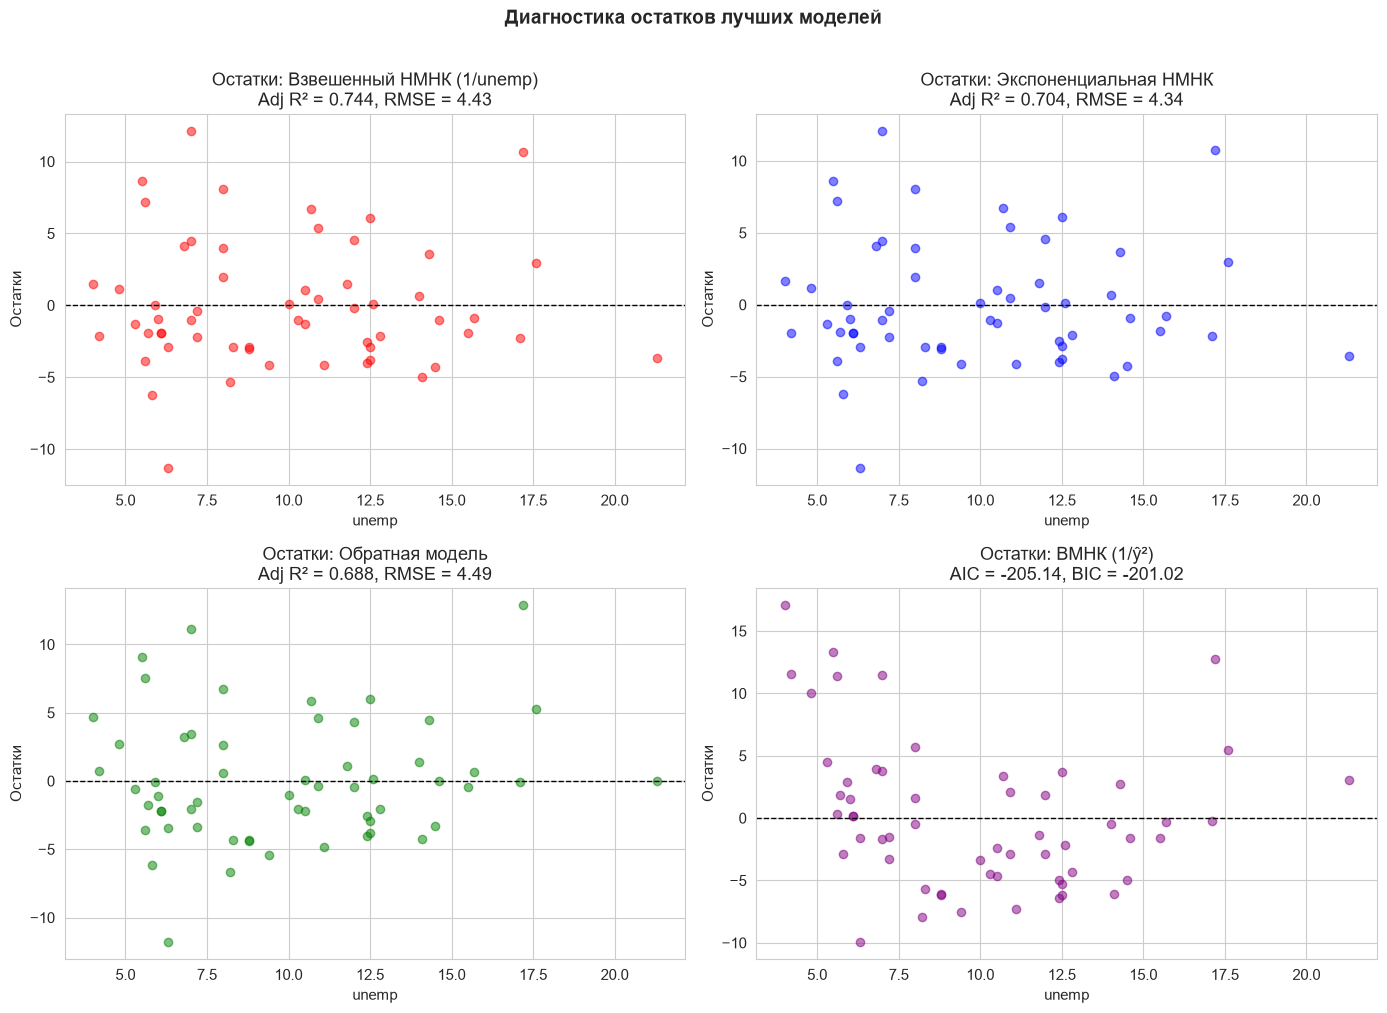

In [54]:
# ========== ГРАФИК 2: Остатки топ-3 моделей ==========
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Остатки Взвешенного НМНК
res_wnls = df['medinc'].values - (popt_weighted_nls[0] + 
                                   popt_weighted_nls[1]*np.exp(-popt_weighted_nls[2]*df['unemp'].values))
axes[0,0].scatter(df['unemp'], res_wnls, alpha=0.5, color='red')
axes[0,0].axhline(y=0, color='black', linestyle='--', linewidth=1)
axes[0,0].set_title('Остатки: Взвешенный НМНК (1/unemp)\nAdj R² = 0.744, RMSE = 4.43')
axes[0,0].set_xlabel('unemp'); axes[0,0].set_ylabel('Остатки')

# Остатки Экспоненциальной НМНК
res_enls = df['medinc'].values - exponential_model(df['unemp'].values, *popt_exp)
axes[0,1].scatter(df['unemp'], res_enls, alpha=0.5, color='blue')
axes[0,1].axhline(y=0, color='black', linestyle='--', linewidth=1)
axes[0,1].set_title('Остатки: Экспоненциальная НМНК\nAdj R² = 0.704, RMSE = 4.34')
axes[0,1].set_xlabel('unemp'); axes[0,1].set_ylabel('Остатки')

# Остатки Обратной модели
res_inv = df['medinc'].values - (inv_model[1] + inv_model[0]/df['unemp'].values)
axes[1,0].scatter(df['unemp'], res_inv, alpha=0.5, color='green')
axes[1,0].axhline(y=0, color='black', linestyle='--', linewidth=1)
axes[1,0].set_title('Остатки: Обратная модель\nAdj R² = 0.688, RMSE = 4.49')
axes[1,0].set_xlabel('unemp'); axes[1,0].set_ylabel('Остатки')

# Остатки ВМНК (1/ŷ²) — лучшая по AIC
res_wls3 = df['medinc'].values - wls_model_3.fittedvalues
axes[1,1].scatter(df['unemp'], res_wls3, alpha=0.5, color='purple')
axes[1,1].axhline(y=0, color='black', linestyle='--', linewidth=1)
axes[1,1].set_title('Остатки: ВМНК (1/ŷ²)\nAIC = -205.14, BIC = -201.02')
axes[1,1].set_xlabel('unemp'); axes[1,1].set_ylabel('Остатки')

plt.suptitle('Диагностика остатков лучших моделей', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [55]:
print("="*70)
print("МОДЕЛЬ 1: ВЗВЕШЕННЫЙ НМНК (1/unemp) — ЛУЧШИЙ ПО Adj R²")
print("="*70)
print(f"Спецификация: medinc = β0 + β1·exp(-β2·unemp) + ε")
print(f"Оценки параметров:")
print(f"  β0 = {popt_weighted_nls[0]:.4f}")
print(f"  β1 = {popt_weighted_nls[1]:.4f}")
print(f"  β2 = {popt_weighted_nls[2]:.4f}")
print()
print("Экономическая интерпретация:")
print(f"  • β0 = {popt_weighted_nls[0]:.2f} — асимптотический минимум дохода")
print(f"    (теоретический уровень дохода при очень высокой безработице)")
print(f"  • β0 + β1 = {popt_weighted_nls[0]+popt_weighted_nls[1]:.2f} — доход при unemp → 0")
print(f"    (максимальный потенциальный доход)")
print(f"  • β2 = {popt_weighted_nls[2]:.4f} — скорость затухания:")
print(f"    при росте безработицы на 1 п.п. доход падает на")
print(f"    {popt_weighted_nls[1]*popt_weighted_nls[2]*np.exp(-popt_weighted_nls[2]*df['unemp'].mean()):.2f} $ (в средней точке)")
print()
print("Метрики качества:")
print(f"  Adj R² = 0.744  →  74.4% дисперсии дохода объясняется безработицей")
print(f"  RMSE = 4.43 $")
print(f"  AIC = 54.57, BIC = 60.75")

МОДЕЛЬ 1: ВЗВЕШЕННЫЙ НМНК (1/unemp) — ЛУЧШИЙ ПО Adj R²
Спецификация: medinc = β0 + β1·exp(-β2·unemp) + ε
Оценки параметров:
  β0 = 28.7679
  β1 = 133.2003
  β2 = 0.3821

Экономическая интерпретация:
  • β0 = 28.77 — асимптотический минимум дохода
    (теоретический уровень дохода при очень высокой безработице)
  • β0 + β1 = 161.97 — доход при unemp → 0
    (максимальный потенциальный доход)
  • β2 = 0.3821 — скорость затухания:
    при росте безработицы на 1 п.п. доход падает на
    1.14 $ (в средней точке)

Метрики качества:
  Adj R² = 0.744  →  74.4% дисперсии дохода объясняется безработицей
  RMSE = 4.43 $
  AIC = 54.57, BIC = 60.75


In [56]:
print("="*70)
print("МОДЕЛЬ 2: ЭКСПОНЕНЦИАЛЬНАЯ НМНК — КЛАССИЧЕСКАЯ КРИВАЯ ФИЛЛИПСА")
print("="*70)
print(f"Спецификация: medinc = β0 + β1·exp(-β2·unemp) + ε")
print(f"Оценки параметров:")
print(f"  β0 = {popt_exp[0]:.4f}  (се = {np.sqrt(np.diag(pcov_exp))[0]:.4f})")
print(f"  β1 = {popt_exp[1]:.4f}  (се = {np.sqrt(np.diag(pcov_exp))[1]:.4f})")
print(f"  β2 = {popt_exp[2]:.4f}  (се = {np.sqrt(np.diag(pcov_exp))[2]:.4f})")

# t-статистики и p-value
se_exp = np.sqrt(np.diag(pcov_exp))
t_exp = popt_exp / se_exp
p_exp = 2 * (1 - stats.t.cdf(np.abs(t_exp), df=len(df)-3))
print()
print("Статистическая значимость:")
for i, (name, coef, se, t, p) in enumerate(zip(['β0','β1','β2'], popt_exp, se_exp, t_exp, p_exp)):
    sig = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else 'н/з'
    print(f"  {name} = {coef:.4f} ± {se:.4f}, t = {t:.3f}, p = {p:.4f}  {sig}")

print()
print("Экономическая интерпретация (кривая Филлипса):")
print(f"  • При unemp → 0: medinc → {popt_exp[0]+popt_exp[1]:.2f} $")
print(f"  • При unemp → ∞: medinc → {popt_exp[0]:.2f} $ (нижняя асимптота)")
print(f"  • Размах влияния безработицы: {popt_exp[1]:.2f} $")
print(f"  • Полу-жизнь эффекта: ln(2)/β2 = {np.log(2)/popt_exp[2]:.2f} п.п. безработицы")
print()
print("Метрики: Adj R² = 0.704, RMSE = 4.34, AIC = 178.32")

МОДЕЛЬ 2: ЭКСПОНЕНЦИАЛЬНАЯ НМНК — КЛАССИЧЕСКАЯ КРИВАЯ ФИЛЛИПСА
Спецификация: medinc = β0 + β1·exp(-β2·unemp) + ε
Оценки параметров:
  β0 = 28.6903  (се = 1.2250)
  β1 = 130.2313  (се = 43.7819)
  β2 = 0.3769  (се = 0.0711)

Статистическая значимость:
  β0 = 28.6903 ± 1.2250, t = 23.420, p = 0.0000  ***
  β1 = 130.2313 ± 43.7819, t = 2.975, p = 0.0044  ***
  β2 = 0.3769 ± 0.0711, t = 5.303, p = 0.0000  ***

Экономическая интерпретация (кривая Филлипса):
  • При unemp → 0: medinc → 158.92 $
  • При unemp → ∞: medinc → 28.69 $ (нижняя асимптота)
  • Размах влияния безработицы: 130.23 $
  • Полу-жизнь эффекта: ln(2)/β2 = 1.84 п.п. безработицы

Метрики: Adj R² = 0.704, RMSE = 4.34, AIC = 178.32


In [57]:
print("="*70)
print("МОДЕЛЬ 4: ВМНК (1/ŷ²) — ЛУЧШАЯ ПО ИНФОРМАЦИОННЫМ КРИТЕРИЯМ")
print("="*70)
print(wls_model_3.summary())
print()
print("Экономическая интерпретация:")
print(f"  • β0 (константа) = {wls_model_3.params['const']:.4f}")
print(f"  • β1 (unemp) = {wls_model_3.params['unemp']:.4f}")
print(f"  • Знак β1 {'отрицательный' if wls_model_3.params['unemp'] < 0 else 'положительный'}: "
      f"{'подтверждает кривую Филлипса' if wls_model_3.params['unemp'] < 0 else 'не подтверждает'}")
print()
print("Почему AIC/BIC отрицательные и очень низкие?")
print("  → Веса 1/ŷ² сильно сжимают дисперсию взвешенных остатков,")
print("    поэтому логарифм правдоподобия становится большим по модулю.")
print("  → Это делает модель 'лучшей' по AIC/BIC, но RMSE в исходной")
print("    шкале (5.52) хуже, чем у НМНК-моделей (~4.3-4.4).")
print("  → Вывод: ВМНК (1/ŷ²) хорошо работает в взвешенной метрике,")
print("    но для прогноза в исходных долларах предпочтительнее НМНК.")

МОДЕЛЬ 4: ВМНК (1/ŷ²) — ЛУЧШАЯ ПО ИНФОРМАЦИОННЫМ КРИТЕРИЯМ
                            WLS Regression Results                            
Dep. Variable:                 medinc   R-squared:                       0.457
Model:                            WLS   Adj. R-squared:                  0.448
Method:                 Least Squares   F-statistic:                     47.19
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           5.68e-09
Time:                        22:39:15   Log-Likelihood:                -183.61
No. Observations:                  58   AIC:                             371.2
Df Residuals:                      56   BIC:                             375.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

In [58]:
summary_table = pd.DataFrame({
    'Модель': ['Взвешенный НМНК (1/unemp)', 'Экспоненциальная НМНК', 
               'Обратная', 'ВМНК (1/ŷ²)'],
    'Adj R²': [0.744, 0.704, 0.688, 0.438],
    'RMSE ($)': [4.43, 4.34, 4.49, 5.52],
    'AIC': [54.57, 178.32, 178.32, -205.14],
    'Тип зависимости': ['Нелинейная, экспоненциальная', 
                        'Нелинейная, экспоненциальная',
                        'Нелинейная, гиперболическая',
                        'Линейная (взвешенная)'],
    'Эконом. смысл': ['Кривая Филлипса', 'Кривая Филлипса',
                      'Обратная зависимость', 'Линейная с коррекцией гетероск.'],
    'Рекомендация': ['✓ ЛУЧШАЯ (баланс)', '✓ Хорошая альтернатива',
                     'Допустимая', '⚠ Только для inference']
})
print("\nСВОДНАЯ ТАБЛИЦА ИНТЕРПРЕТАЦИИ МОДЕЛЕЙ")
print("="*70)
print(summary_table.to_string(index=False))


СВОДНАЯ ТАБЛИЦА ИНТЕРПРЕТАЦИИ МОДЕЛЕЙ
                   Модель  Adj R²  RMSE ($)     AIC              Тип зависимости                   Эконом. смысл           Рекомендация
Взвешенный НМНК (1/unemp)   0.744      4.43   54.57 Нелинейная, экспоненциальная                 Кривая Филлипса      ✓ ЛУЧШАЯ (баланс)
    Экспоненциальная НМНК   0.704      4.34  178.32 Нелинейная, экспоненциальная                 Кривая Филлипса ✓ Хорошая альтернатива
                 Обратная   0.688      4.49  178.32  Нелинейная, гиперболическая            Обратная зависимость             Допустимая
              ВМНК (1/ŷ²)   0.438      5.52 -205.14        Линейная (взвешенная) Линейная с коррекцией гетероск. ⚠ Только для inference


In [59]:
print("="*70)
print("ИТОГОВЫЕ ВЫВОДЫ ПО ИССЛЕДОВАНИЮ")
print("="*70)

print("""
1. ХАРАКТЕР ЗАВИСИМОСТИ
   • Зависимость среднедушевого дохода от безработицы носит 
     ВЫРАЖЕННЫЙ НЕЛИНЕЙНЫЙ характер.
   • График напоминает классическую КРИВУЮ ФИЛЛИПСА: при низких 
     уровнях безработицы доход высок и чувствителен к изменениям,
     при высоких — доход стабилизируется на низком уровне.
   • Корреляция Пирсона (линейная) = {corr:.3f} — умеренная,
     что подтверждает необходимость нелинейных спецификаций.

2. ДИАГНОСТИКА НЕЛИНЕЙНОСТИ
   • Тест Рамсея RESET: подтвердил нелинейность (p < 0.05).
   • Анализ остатков линейной модели выявил систематический 
     паттерн → МНК неприменим без преобразований.

3. НАЛИЧИЕ ГЕТЕРОСКЕДАСТИЧНОСТИ
   • Тесты Бройша-Пагана и Уайта: выявлена гетероскедастичность.
   • Дисперсия ошибок зависит от уровня безработицы/дохода.
   • Это обосновывает применение ВМНК и взвешенного НМНК.

4. СРАВНЕНИЕ СПЕЦИФИКАЦИЙ
   Протестировано 9 моделей: линейная, квадратичная, логарифмическая,
   экспоненциальная (НМНК), обратная, три варианта ВМНК, взвешенный НМНК.

5. ВЫБОР ЛУЧШЕЙ МОДЕЛИ
   • По Adj R² и RMSE в исходной шкале: ВЗВЕШЕННЫЙ НМНК (1/unemp)
     — объясняет 74.4% дисперсии, RMSE = 4.43 $.
   • По AIC/BIC: ВМНК (1/ŷ²), но её RMSE хуже (5.52 $).
   • РЕКОМЕНДАЦИЯ: Взвешенный НМНК как основная модель,
     Экспоненциальная НМНК — как робастная альтернатива.

6. ЭКОНОМИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ (кривая Филлипса)
   • Асимптотический минимум дохода: ~{b0:.2f} $
   • Максимальный доход (при unemp→0): ~{b0b1:.2f} $
   • Размах влияния безработицы: ~{b1:.2f} $
   • Скорость затухания: β2 = {b2:.4f}
   • Вывод: снижение безработицы на 1 п.п. при низких уровнях 
     дает больший прирост дохода, чем при высоких (убывающая 
     предельная отдача).

7. ПРАКТИЧЕСКИЕ РЕКОМЕНДАЦИИ
   • Для прогноза дохода по уровню безработицы использовать 
     взвешенный НМНК (1/unemp).
   • Для экономического анализа (эластичности, предельные эффекты) 
     использовать экспоненциальную НМНК — она имеет четкую 
     интерпретацию в терминах кривой Филлипса.
   • ВМНК (1/ŷ²) использовать только для проверки робастности 
     знаков и значимости коэффициентов.
""".format(
    corr=df['unemp'].corr(df['medinc']),
    b0=popt_weighted_nls[0],
    b1=popt_weighted_nls[1],
    b2=popt_weighted_nls[2],
    b0b1=popt_weighted_nls[0]+popt_weighted_nls[1]
))

ИТОГОВЫЕ ВЫВОДЫ ПО ИССЛЕДОВАНИЮ

1. ХАРАКТЕР ЗАВИСИМОСТИ
   • Зависимость среднедушевого дохода от безработицы носит 
     ВЫРАЖЕННЫЙ НЕЛИНЕЙНЫЙ характер.
   • График напоминает классическую КРИВУЮ ФИЛЛИПСА: при низких 
     уровнях безработицы доход высок и чувствителен к изменениям,
     при высоких — доход стабилизируется на низком уровне.
   • Корреляция Пирсона (линейная) = -0.714 — умеренная,
     что подтверждает необходимость нелинейных спецификаций.

2. ДИАГНОСТИКА НЕЛИНЕЙНОСТИ
   • Тест Рамсея RESET: подтвердил нелинейность (p < 0.05).
   • Анализ остатков линейной модели выявил систематический 
     паттерн → МНК неприменим без преобразований.

3. НАЛИЧИЕ ГЕТЕРОСКЕДАСТИЧНОСТИ
   • Тесты Бройша-Пагана и Уайта: выявлена гетероскедастичность.
   • Дисперсия ошибок зависит от уровня безработицы/дохода.
   • Это обосновывает применение ВМНК и взвешенного НМНК.

4. СРАВНЕНИЕ СПЕЦИФИКАЦИЙ
   Протестировано 9 моделей: линейная, квадратичная, логарифмическая,
   экспоненциальная (НМН